# TIGER/Line

---
*The Census Bureau is the US's national statistics office.*
*TIGER (Topologically Integrated Geographic Encoding and Referencing) is the Census Bureau's map database. This study uses its tract file, and the Census Bureau's simplified 2020 state outlines (cartographic boundary file):*
- ***tracts**: every census tract, with its outlines and 11-digit id (`GEOID`)* `data/0_raw/1_2_tiger/tracts_2022.gpkg` (downloaded 17 October 2026)
- ***states**: every state, DC and the 5 territories, with their outlines, two-letter code (CA) and 2-digit number (06), simplified* `data/0_raw/1_2_tiger/states_2020.gpkg`

The states file ships with the project. The tract file is 713MB, so the notebook downloads it.

<hr style="border:none; border-top:0.5px solid #999">

The notebook:
- downloads the tract file (skipped if it exists) and loads it
- Los Angeles County's tract outlines and deaths visual → <span style="color:yellow">tract_outlines.png</span>
- <span style="color:red">**saves**</span> `data/1_data_notebooks/1_2_tiger/tracts.gpkg` (+ `states.gpkg`): the tract outlines with their id and land area, and the state outlines for the plots

<hr style="border:none; border-top:0.5px solid #999">

The tract columns needed for the steps below:

| Column | What it holds | Used for                                                                                       |
|---|---|------------------------------------------------------------------------------------------------|
| `STATEFP` | the state's 2-digit number (06 = California) | LA filter                                                                                      |
| `COUNTYFP` | the county's 3-digit number inside its state (037 = Los Angeles) | LA filter                                                                                      |
| `GEOID` | the state, county and 6-digit tract codes joined: the tract's 11-digit id | used in 1_3 (does ACS hold every tract) and 2_join_and_roles (which tract each death falls in) |
| `ALAND` | the tract's land area in m², saved as `tract_land_area` | used in 1_3 (the density tails check) and 2_join_and_roles (`pop_density`)                     |
| `geometry` | the tract's outline | LA map; used also in 2_join_and_roles (which tract each death falls in)                        |

### Imports and setup

---
- Applies the shared plot style

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pygris

from shared.paths import TIGER_RAW_DIR, MPV_DIR, TIGER_DIR, OUTPUTS_DIR
from shared.plotting import setup_plotting, save_fig, PALETTE

setup_plotting()

OUT_DIR = OUTPUTS_DIR / "1_2_tiger"

TIGER_PATH = TIGER_RAW_DIR / "tracts_2022.gpkg"

### Download and load the tract file

---
- **From the Census Bureau through pygris,** one state at a time: the 50 states and DC, TIGER/Line 2022, full detail
- Loads every tract with its shape

In [2]:
US_STATES_PLUS_DC = (
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC",
)

if TIGER_PATH.exists():
    print(f"[SKIP] {TIGER_PATH.name} already exists.")
else:
    per_state = [pygris.tracts(state=state, year=2022, cache=True) for state in US_STATES_PLUS_DC]

    all_tracts = pd.concat(per_state)
    all_tracts.to_file(TIGER_PATH)
    print(f"Wrote {TIGER_PATH.name}: {len(all_tracts):,} tracts")

tracts = gpd.read_file(TIGER_PATH)

[SKIP] tracts_2022.gpkg already exists.


### Tract outlines → <span style="color:yellow">tract_outlines.png</span>

---
Showing Los Angeles County because it is the most populous in the US.

**Small tracts in the dense city, large ones at the rural edge;** the deaths gather in the city.

LA County tracts: 2,498


Deaths drawn: 321


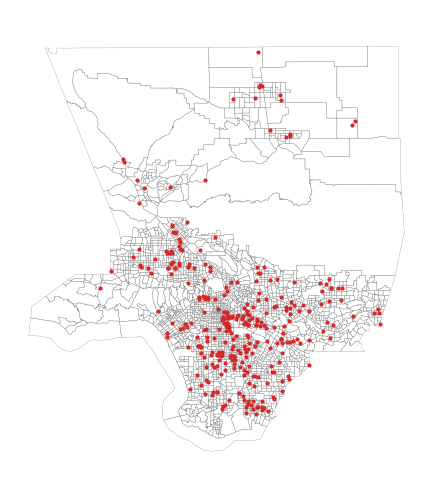

In [3]:
la_tracts = tracts[(tracts["STATEFP"] == "06") & (tracts["COUNTYFP"] == "037")]
print(f"LA County tracts: {len(la_tracts):,}")

mpv = pd.read_parquet(MPV_DIR / "mpv.parquet")

lonlat = gpd.points_from_xy(mpv["longitude"], mpv["latitude"])
deaths_gdf = gpd.GeoDataFrame(mpv, geometry=lonlat, crs=la_tracts.crs)

# `union_all()` merges the county's tracts into one shape
in_la = deaths_gdf[deaths_gdf.intersects(la_tracts.union_all())]
print(f"Deaths drawn: {len(in_la):,}")

fig, ax = plt.subplots()
la_tracts.plot(ax=ax, facecolor="none", edgecolor="gray", linewidth=0.2)
in_la.plot(ax=ax, color=PALETTE[1], markersize=4)
ax.set_ylim(bottom=33.6)  # leaves out two islands far to the south that shrink the mainland
ax.set_axis_off()
save_fig(fig, "tract_outlines", OUT_DIR)

### Save the selections

---
- `data/1_data_notebooks/1_2_tiger/tracts.gpkg`: every tract, its 11-digit id `tract_id` (TIGER's `GEOID`), its land area `tract_land_area` (TIGER's `ALAND`, m²) and its outline, in the Census coordinate system as published
- `data/1_data_notebooks/1_2_tiger/states.gpkg`: the outlines of the 50 states and DC with their two-letter code `STUSPS`, as visual support for the plots

In [4]:
tract_selection = tracts[["GEOID", "ALAND", "geometry"]].rename(columns={"GEOID": "tract_id", "ALAND": "tract_land_area"})
tract_selection.to_file(TIGER_DIR / "tracts.gpkg")
print(f"Saved data/1_data_notebooks/1_2_tiger/tracts.gpkg: {len(tract_selection):,} tracts × {tract_selection.shape[1]} columns")

states = gpd.read_file(TIGER_RAW_DIR / "states_2020.gpkg")[["STUSPS", "geometry"]]
states = states[states["STUSPS"].isin(US_STATES_PLUS_DC)]  # like the tracts: the 5 territories hold no MPV death
states.to_file(TIGER_DIR / "states.gpkg")
print(f"Saved data/1_data_notebooks/1_2_tiger/states.gpkg: {len(states)} outlines (50 states + DC) × {states.shape[1]} columns")

Saved data/1_data_notebooks/1_2_tiger/tracts.gpkg: 84,415 tracts × 3 columns
Saved data/1_data_notebooks/1_2_tiger/states.gpkg: 51 outlines (50 states + DC) × 2 columns
